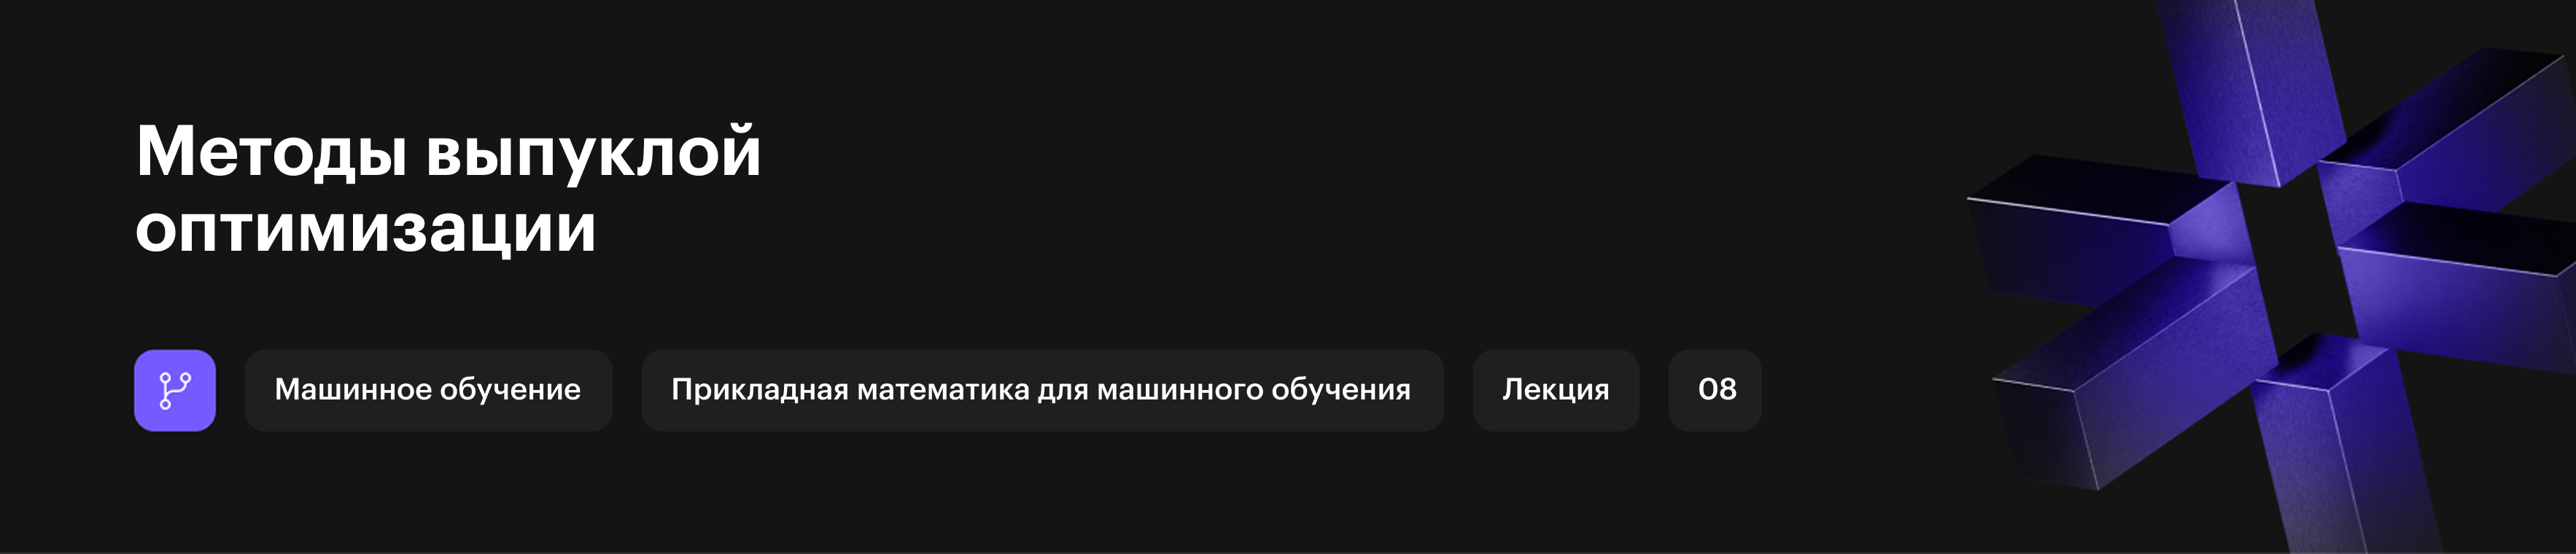

# Базовые функции из видео

In [ ]:
import math
import numpy as np

import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.path import Path
import matplotlib.animation as animation
from IPython.display import HTML

from scipy import optimize

from typing import Callable, Optional

In [ ]:
def get_path_animation(points: np.array, f_level: Callable, levels: int = 20,
                       name: str = "", n_points_axis=100) -> animation.FuncAnimation:
    """ Отрисовка динамического пути в двухмерном пространстве

    Args:
      points: набор точек, которые образуют путь.
      f_level: функция для отображения уровней.
      levels: число уровней функции.
      name: Название траектории.
      n_points_axis: Число точек на оси для отрисовки линии уровня.

    Returns:
      Динамический график пути.
    """
    sns.set(style="darkgrid")
    fig = plt.figure(figsize=(13, 6))

    # Адаптация окна просмотра
    left_bottom = np.array(points).min(axis=0)
    right_up = np.array(points).max(axis=0)
    diff = np.max(right_up - left_bottom)
    left_bottom -= 0.1 * diff
    right_up += 0.1 * diff

    path_x1 = points[:,0]
    paht_x2 = points[:,1]

    # Отрисовка линий уровня
    x1 = np.linspace(left_bottom[0], right_up[0], n_points_axis)
    x2 = np.linspace(left_bottom[1], right_up[1], n_points_axis)
    X1, X2 = np.meshgrid(x1, x2)
    # Вариант удобнее
    # Z = f_level([X1, X2])
    # Вариант универсальнее
    Z = np.zeros([n_points_axis, n_points_axis])
    for i in range(n_points_axis):
        for j in range(n_points_axis):
            Z[i,j] = f_level(np.array([X1[i,j], X2[i,j]]))

    def update(frame):
        # Постоянное отображение на графике
        plt.xlim(left_bottom[0], right_up[0])
        plt.ylim(left_bottom[1], right_up[1])
        plt.axis('scaled')
        # Внешний вид
        plt.xlabel("x1", size=15)
        plt.ylabel("x2", size=15)
        plt.title(f"Траектория. {name}", size=25)
        plt.contour(X1, X2, Z, levels=levels)
        # Обновление данных
        plt.plot(path_x1[:frame + 1], paht_x2[:frame + 1], color = "green")
        plt.scatter(path_x1[:frame + 1], paht_x2[:frame + 1], color = "green")


    ani = animation.FuncAnimation(fig=fig, func=update, frames=len(points), interval=240)
    return ani

In [ ]:
def get_full_path(points: np.array, f_level: Callable,
                  levels=20, name: str = "", n_points_axis=100) -> animation.FuncAnimation:
    """ Отрисовка всего пути в двухмерном пространстве

    Args:
      points: набор точек, которые образуют путь.
      f_level: функция для отображения уровней.
      levels: число уровней функции.
      name: название траектории.
      n_points_axis: Число точек на оси для отрисовки линии уровня.
    """
    sns.set(style="darkgrid")
    fig = plt.figure(figsize=(7, 5))

    # Адаптация окна просмотра
    left_bottom = np.array(points).min(axis=0)
    right_up = np.array(points).max(axis=0)
    diff = np.max(right_up - left_bottom)
    left_bottom -= 0.1 * diff
    right_up += 0.1 * diff

    path_x1 = points[:,0]
    paht_x2 = points[:,1]

    # Отрисовка линий уровня
    x1 = np.linspace(left_bottom[0], right_up[0], n_points_axis)
    x2 = np.linspace(left_bottom[1], right_up[1], n_points_axis)
    X1, X2 = np.meshgrid(x1, x2)
    # Вариант удобнее
    # Z = f_level([X1, X2])
    # Вариант универсальнее
    Z = np.zeros([n_points_axis, n_points_axis])
    for i in range(n_points_axis):
        for j in range(n_points_axis):
            Z[i,j] = f_level(np.array([X1[i,j], X2[i,j]]))

    plt.xlim(left_bottom[0], right_up[0])
    plt.ylim(left_bottom[1], right_up[1])
    plt.axis('scaled')
    # Внешний вид
    plt.xlabel("x1", size=15)
    plt.ylabel("x2", size=15)
    plt.title(f"Траектория. {name}", size=25)
    plt.contour(X1, X2, Z, levels=levels)
    # for each frame, update the data stored on each artist.
    plt.plot(path_x1, paht_x2, color = "green")
    plt.scatter(path_x1, paht_x2, color = "green")


In [ ]:
def common_gradient(f: Callable, x: np.array, h: float = 1e-6) -> np.array:
    """ Вычисление приближенного значения градиента функции

    Args:
      f: функция для которой будет высчитываться градиент.
      x: точка, в которой градиент будет посчитан.
      h: размер шага при построении градиента.

    Returns:
      np.array: градиент функции в точке.
    """
    grad = []
    for i in range(len(x)):
        e_i = np.zeros(len(x))
        e_i[i] = 1
        grad.append((f(x+h*e_i) - f(x-h*e_i)) / (2*h))
    return np.array(grad)

In [ ]:
def discrete_gd(f: Callable, grad_f: Callable, x0: np.array, alpha: float,
                n_iter: int = 1_000, delta: float = 1e-4) -> tuple[np.array, float, int, list]:
    """ Градиентный метод с дискретным шагом

    Args:
      f: минимизируемая функция.
      grad_f: функция вычисления градиента функции.
      x0: начальное приближение.
      alpha: шаг градиентного метода.
      n_iter: максимальное число итераций.
      delta: требуемая точность по норме градиента для останова алгоритма.

    Returns:
      - **x_k** -- точка решения градиентного метода.
      - **f(x_k)** -- значение функции в полученной точке.
      - **count_iter** -- число проведенных итераций.
      - **x_hist** -- история движения градиентного спуска.
    """
    count_iter = 0
    x_k = x0
    x_hist = [x0]
    for i in range(n_iter):
        count_iter += 1
        grad = grad_f(f, x_k)
        x_k = x_k - alpha * grad
        x_hist.append(x_k)
        # Условие останова по норме градиента
        if np.linalg.norm(grad) < delta:
            break
    return x_k, f(x_k), count_iter, x_hist

In [ ]:
def crushing_gd(f: Callable, grad_f: Callable, x0: np.array, beta: float, lamda: float, epsilon: float=0.5,
                n_iter: int = 1_000, delta: float = 1e-4) -> tuple[np.array, float, int, list, int, list]:
    """ Градиентный метод с дроблением шага

    Args:
      f: минимизируемая функция.
      grad_f: функция вычисления градиента функции.
      x0: начальное приближение.
      alpha: шаг градиентного метода.
      beta: начальное значение коэффициента alpha.
      lamda: шаг уменьшения коэффициента alpha по формуле alpha=lamda * alpha.
      epsilon: параметр неравенства, необходимого для остановки дробления alpha&
      n_iter: максимальное число итераций.
      delta: требуемая точность по норме градиента для останова алгоритма.

    Returns:
      - **x_k** -- точка решения градиентного метода.
      - **f(x_k)** -- значение функции в полученной точке.
      - **count_iter** -- число проведенных итераций.
      - **x_hist** -- история движения градиентного спуска.
      - **count_search** -- история движения градиентного спуска.
      - **alpha_hist** -- история коэффициентов градиентного спуска.
    """
    count_iter = 0
    count_search = 0
    x_k = x0
    x_hist = [x0]
    alpha_k = beta
    alpha_hist = []
    for i in range(n_iter):
        count_iter += 1
        grad = grad_f(f, x_k)
        norm_grad_2 = np.linalg.norm(grad)**2

        # Проверка неравенства
        while True:
            if f(x_k - alpha_k * grad) - f(x_k) <= -epsilon * alpha_k * norm_grad_2:
                break
            alpha_k = lamda * alpha_k
            count_search += 1
        alpha_hist.append(alpha_k)
        x_k = x_k - alpha_k * grad
        x_hist.append(x_k)

        # Критерий останова
        if np.linalg.norm(grad) < delta:
            break
    return x_k, f(x_k), count_iter, x_hist, count_search, alpha_hist

# Примеры функций

Функция $f_1(x) = x_1^2 + x_2^2$.

Число обусловленности = 1 из собственных значений матрицы Гессе.

$\nabla^2 f(x) = \Big( \array{2 & 0 \\ 0 & 2} \Big)$.

$\lambda_{max} / \lambda_{min} = {2 \over 2} = 1$.

In [ ]:
def f1(x):
  return x[0] ** 2 + x[1] ** 2

#### **Вопрос.** Какие параметры приведут к наиcкорейшей сходимости?

Можно менять
начальное приближение, коэффициент бета, коэффициент лямбда.

Воспользуемся основой для рассмотрения функции, далее можно менять входные параметры.

In [ ]:
x_k, f_x_k, count_iter, x_hist, count_search, alpha_hist = crushing_gd(
    f=f1,
    grad_f=common_gradient,
    x0=np.array([10,15]),
    beta=1,
    lamda=0.7,
    epsilon=0.5,
    n_iter=1000
)

In [ ]:
print(f"Решение найдено за {count_iter} шагов") # Ещё нужно проверить корректность

Решение найдено за 5 шагов


In [ ]:
count_search

2

In [ ]:
alpha_hist

[0.48999999999999994,
 0.48999999999999994,
 0.48999999999999994,
 0.48999999999999994,
 0.48999999999999994]

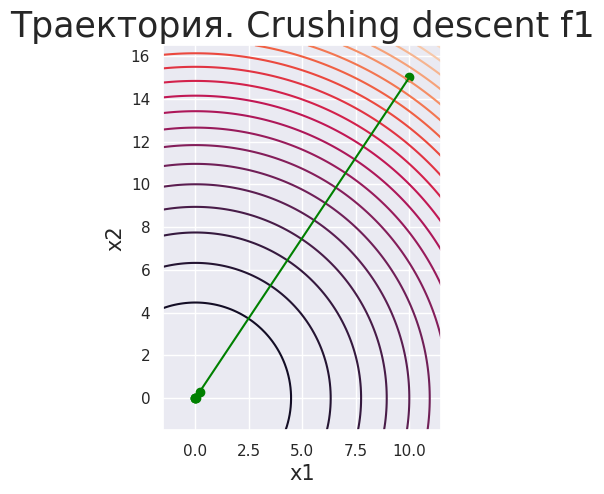

In [ ]:
get_full_path(np.array(x_hist), f1, name="Crushing descent f1")

Функция $f_2(x) = 1000x_1^2 + x_2^2$.

Число обусловленности = 1000 из собственных значений матрицы Гессе.

$\nabla^2 f(x) = \Big( \array{2000 & 0 \\ 0 & 2} \Big)$.

$\lambda_{max} / \lambda_{min} = {2000 \over 2} = 1000$.

In [ ]:
def f2(x):
  return 1000*x[0] ** 2 + x[1] ** 2

#### **Вопрос.** Какие параметры приведут к наиcкорейшей сходимости?

Можно менять
начальное приближение, коэффициент бета, коэффициент лямбда.

In [ ]:
x_k_2, f_x_k_2, count_iter_2, x_hist_2, count_search_2, alpha_hist_2 = crushing_gd(
    f=f2,
    grad_f=common_gradient,
    x0=np.array([10,15]),
    beta=1,
    lamda=0.7,
    epsilon=0.5,
    n_iter=30_000
)

In [ ]:
print(f"Решение найдено за {count_iter_2} шагов") # Ещё нужно проверить корректность

Решение найдено за 16123 шагов


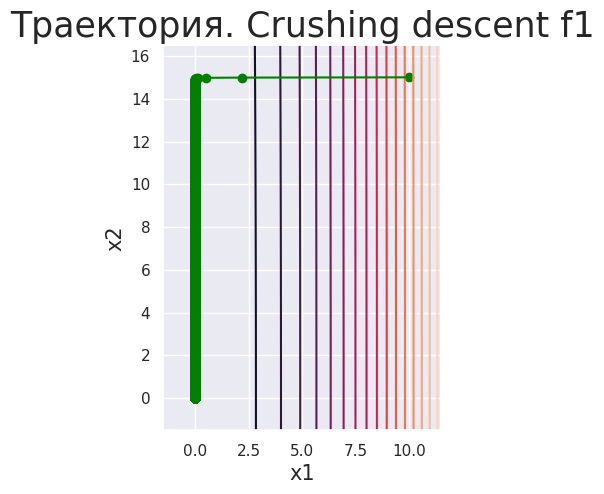

In [ ]:
get_full_path(np.array(x_hist_2), f2, name="Crushing descent f1")

#### Продолжение

Рассмотрим невыпуклую функцию.

Для тестов методов есть специальные функции, которыми можно пользоваться. Список — [здесь](https://ru.wikipedia.org/wiki/Тестовые_функции_для_оптимизации).

Возьмём функцию Растригина: у неё много локальных минимумов, один глобальный в точке $(0,0)$.

$f_3(x) = 20 + x_1^2 - 10cos(2\pi x_1) + x_2^2 - 10cos(2\pi x_2)$.

In [ ]:
def f3(x):
  return 20 + x[0] ** 2 - 10 * math.cos(2 * math.pi * x[0])  + x[1] ** 2 - 10 * math.cos(2 * math.pi * x[1])

#### **Вопрос.** Какие параметры приведут к наиcкорейшей сходимости?

Можно менять
начальное приближение, коэффициент бета, коэффициент лямбда.

In [ ]:
x_k_3, f_x_k_3, count_iter_3, x_hist_3, count_search_3, alpha_hist_3 = crushing_gd(
    f=f3,
    grad_f=common_gradient,
    x0=np.array([0.5,1]),
    beta=1,
    lamda=0.9,
    epsilon=0.5,
    n_iter=30_000
)

In [ ]:
print(f"Решение найдено за {count_iter_3} шагов") # Ещё нужно проверить корректность

Решение найдено за 7 шагов


In [ ]:
print(f"Решение {x_k_3=}")

Решение x_k_3=array([ 1.43437579e-09, -2.94416140e-10])


In [ ]:
# Проверим градиент в точке
common_gradient(f=f3, x=x_k_3)

array([ 5.68434189e-07, -1.17239551e-07])

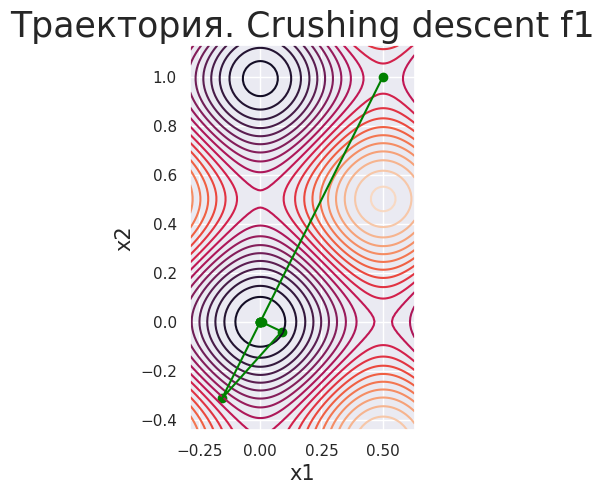

In [ ]:
get_full_path(np.array(x_hist_3), f3, name="Crushing descent f1")

# Линейная регрессия библиотечными методами

Сгенерируем тестовый датасет.

In [ ]:
# Вводные
size = 1000 # Размер датасета
features = 30 # Число признаков

# Генерация тестовых значений
X_test = np.random.randn(size, features)
y_test = X_test @ np.random.randn(features) + np.random.randn(size) * 0.1

В многомерном случае уже не так просто отрисовать.

**Вариант 1.** sklearn.linear_model.LinearRegression: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html.

In [ ]:
from sklearn.linear_model import LinearRegression

reg = LinearRegression().fit(X_test, y_test)

In [ ]:
# Решение
reg.coef_

array([ 0.69216381, -0.22272807, -1.48178927, -0.45986791,  0.78404587,
        0.54691544,  0.5736676 , -0.10407869, -1.0977688 , -0.6489985 ,
        0.63344763,  0.36879731, -1.15539056,  0.2470263 , -0.26315136,
        0.01692986, -0.20580376,  0.17370584,  1.07855956, -1.48644577,
        2.49529721,  1.03429465,  0.81739756, -0.83695264, -1.02193028,
        0.21273217, -0.04447848, -0.53800386, -0.51838909, -0.4091079 ])

In [ ]:
# Свободный член
reg.intercept_

np.float64(0.0005958945277020761)

При изучении документации использует внутри scipy.linalg.lstsq.

**Вариант 2.** scipy.linalg.lstsq: https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.lstsq.html.

Внутри используется аналитическое решение через SVD-разложение.

$X^TXw = X^Tb$ — уравнение для линейной регрессии.
Используется SVD-разложение (было в предыдущих темах).

$X = USV$.

Подставив в решение изначальной СЛАУ и помня, что $UU^T=I$, $VV^T=I$,

$w = (X^TX)^{-1}X^Tb = (V^TS^TU^TUSV)^{-1}V^TS^TU^Tb = (V^{-1}S^{-1}{S^T}^{-1}{V^T}^{-1})V^TS^TU^Tb = V^{-1}S^{-1}U^Tb = V^TS^{-1}U^Tb$.

In [ ]:
from scipy.linalg import lstsq

# Решение, остатки, эффективный ранг, сингулярные значения
solution, residues, rnk, s = lstsq(X_test, y_test)

In [ ]:
solution

array([ 0.69217575, -0.22274878, -1.48183419, -0.45985764,  0.78402074,
        0.54689905,  0.57371334, -0.10406836, -1.09775675, -0.64898407,
        0.63346801,  0.36879309, -1.15540298,  0.24702836, -0.26312784,
        0.01696975, -0.20581024,  0.1737262 ,  1.07852744, -1.48645333,
        2.49529834,  1.03429163,  0.81740311, -0.8369316 , -1.02193087,
        0.21272803, -0.04447651, -0.53799988, -0.51836082, -0.40910913])

In [ ]:
residues

np.float64(9.24361285097949)

In [ ]:
rnk

30

In [ ]:
s

array([36.33383953, 35.87887438, 35.58150401, 35.31230753, 34.58393858,
       34.39186489, 34.22427329, 33.72861312, 33.52540711, 32.94427454,
       32.67765104, 32.36278931, 31.99220495, 31.64474861, 31.54308162,
       31.27707045, 31.07129183, 30.54545336, 30.29693947, 30.28142549,
       29.89714692, 29.77950403, 29.34983747, 28.80134536, 28.4716346 ,
       28.31405035, 27.6068166 , 27.27271418, 26.99960413, 26.83381175])

**Вариант 3.** Как в примере видеолекций, через собственную реализацию градиентного спуска.


**Вариант 4.** sklearn.linear_model.SGDRegressor: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDRegressor.html.

По умолчанию он использует стохастический градиентный спуск, который будет изучен дальше. Но главное — под капотом градиентная идея.

In [ ]:
from sklearn.linear_model import SGDRegressor

sgd = SGDRegressor(
    learning_rate='constant',
    penalty=None, # Без регуляризации
    shuffle=False, # не перемешивать данные
    eta0=0.01, # С такой константой будет градиентный спуск с детерминированным шагом
    random_state=42
)

sgd.fit(X_test, y_test)

SGDRegressor(learning_rate='constant', penalty=None, random_state=42,
             shuffle=False)

In [ ]:
# Решение через градиенты
sgd.coef_

array([ 0.68839821, -0.21975698, -1.48439025, -0.46282846,  0.79310893,
        0.54209118,  0.57437842, -0.10517891, -1.09954632, -0.64949744,
        0.62549834,  0.35969638, -1.16729328,  0.23056542, -0.25607429,
        0.00716463, -0.2029445 ,  0.17271809,  1.07001482, -1.49313214,
        2.49925644,  1.03552852,  0.82634374, -0.82748301, -1.02694951,
        0.21026212, -0.04496713, -0.54830519, -0.52212449, -0.41925232])

Тут уже есть некоторые отличия от аналитических решений.

# Реализация наискорейшего спуска


Нужно научиться составлять и решать задачу одномерной оптимизации на каждом шаге градиентного спуска.

scipy.optimize.minimize_scalar можно использовать для одномерной оптимизации: https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize_scalar.html.

#### **Вопрос.** Как можно дополнить функцию обычного градиентного спуска, чтобы он стал наискорейшим?


In [ ]:
from scipy.optimize import minimize_scalar

def fast_gd(f: Callable, grad_f: Callable, x0: np.array,
            n_iter: int = 1_000, delta: float = 1e-4) -> tuple[np.array, float, int, list]:
    """ Градиентный метод с дискретным шагом

    Args:
      f: минимизируемая функция.
      grad_f: функция вычисления градиента функции.
      x0: начальное приближение.
      n_iter: максимальное число итераций.
      delta: требуемая точность по норме градиента для останова алгоритма.

    Returns:
      - **x_k** -- точка решения градиентного метода.
      - **f(x_k)** -- значение функции в полученной точке.
      - **count_iter** -- число проведенных итераций.
      - **x_hist** -- история движения градиентного спуска.
    """
    count_iter = 0
    x_k = x0
    x_hist = [x0]
    alpha_hist = [None]
    for i in range(n_iter):
        count_iter += 1
        grad = grad_f(f, x_k)


        # Блок одномерной оптимизации — тут основное изменение
        def search_function(alpha):
            return f(x_k - alpha * grad)

        opt_result = minimize_scalar(search_function,
                                     method='golden')
        alpha_opt = opt_result.x
        alpha_hist.append(alpha_opt)

        x_k = x_k - alpha_opt * grad
        x_hist.append(x_k)
        # Условие останова по норме градиента
        if np.linalg.norm(grad) < delta:
            break
    return x_k, f(x_k), count_iter, x_hist, alpha_hist

In [ ]:
x_k_4, f_x_k_4, count_iter_4, x_hist_4, alpha_hist_4 = fast_gd(
    f=f1, # Одна из старых функций
    grad_f=common_gradient,
    x0=np.array([0.5,1]),
    n_iter=30_000
)

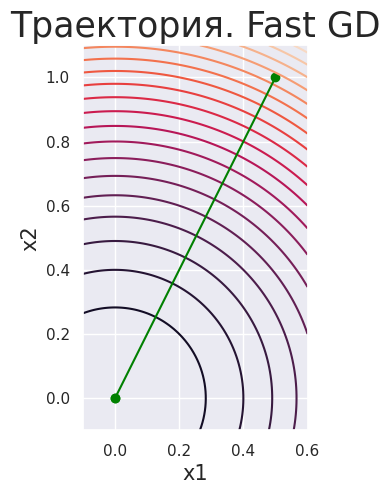

In [ ]:
get_full_path(np.array(x_hist_4), f1, name="Fast GD")

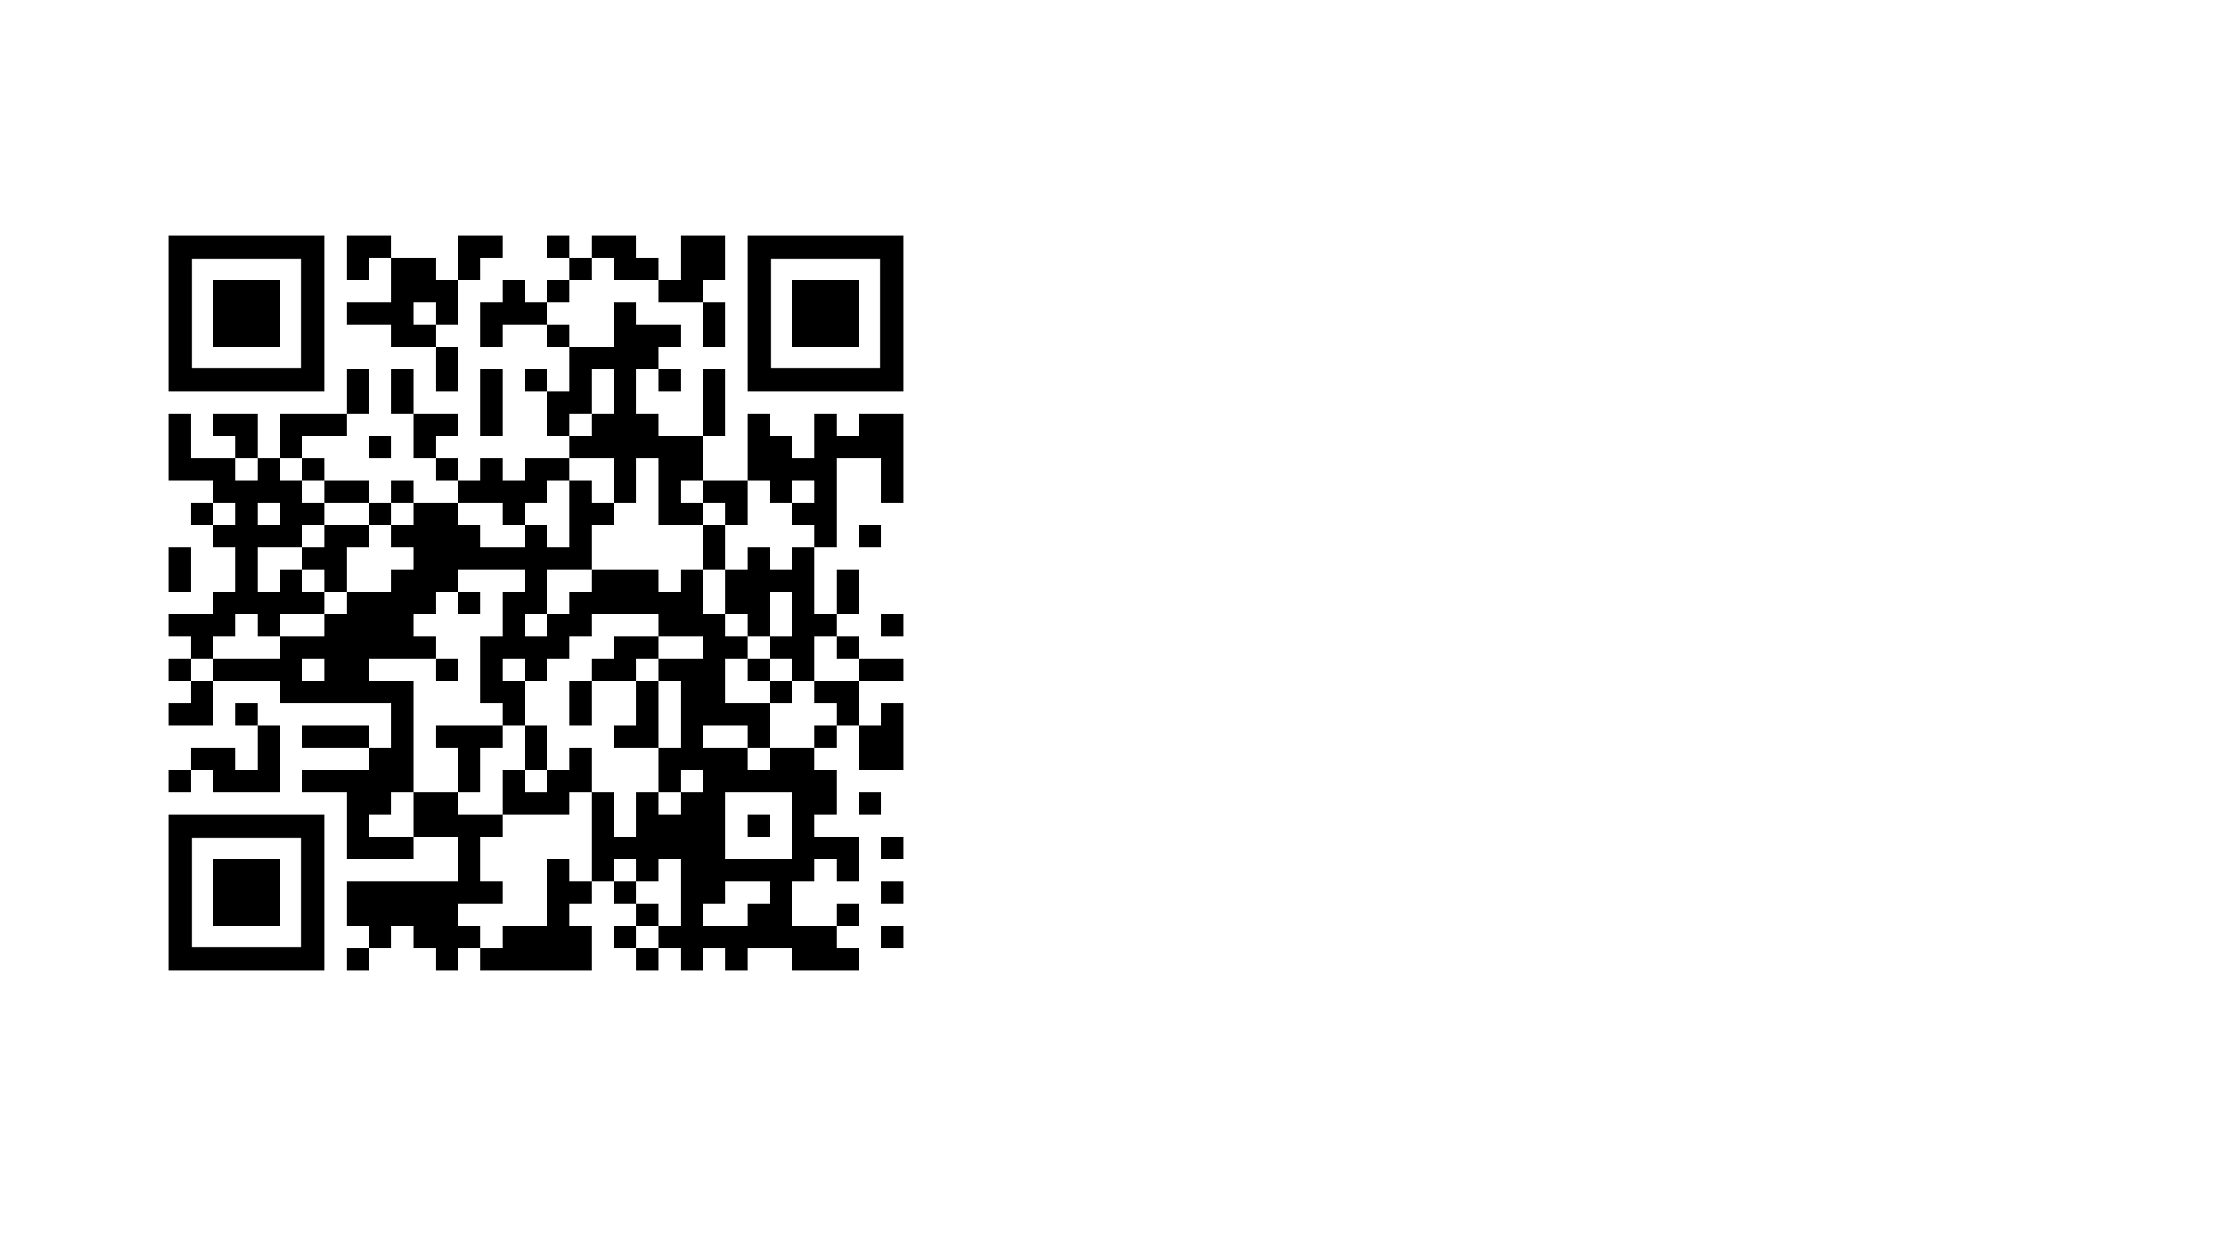